# 15 · Observability for LLM apps: traces, metrics, cost and online evaluation

An LLM application fails in ways normal monitoring does not see: a hallucinated answer is still `HTTP 200`, a prompt change silently doubles the cost, one slow tool drags the p99 latency, a retrieval regression lowers quality for a week before anyone notices. **Observability** means recording enough about every request to answer *what happened, how long it took, what it cost and how good it was* — after the fact.

The standard model (OpenTelemetry, used by LangSmith, Langfuse, Arize Phoenix, Datadog…):

- **trace** — one end-to-end request; **span** — one step inside it (LLM call, retrieval, tool), with timing, attributes and a parent → a tree
- **metrics** — aggregates over spans: latency percentiles, error rate, tokens, cost
- **scores** — quality signals attached to traces: user feedback, heuristic checks, LLM-as-judge

This notebook instruments a small RAG + tools assistant end to end, then uses the data the way an on-call engineer would.

**Source:** `llm_edu_suite/observability.py` (pure Python, no dependencies).

In [1]:
import os, sys, json, time, random
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, ROOT)                     # so `llm_edu_suite` imports from any notebooks/ sub-folder
import numpy as np
import matplotlib.pyplot as plt
random.seed(0); np.random.seed(0)

In [2]:
from llm_edu_suite.observability import Tracer, TracedLLM, instrument_registry, redact_pii, MetricsAggregator, check_slos, percentile
from llm_edu_suite.llm_client import MockLLM
from llm_edu_suite.rag import Retriever, chunk_documents, build_rag_prompt
from llm_edu_suite.agents import ToolRegistry, Agent
from llm_edu_suite.evaluation import token_f1, context_support

docs_dir = os.path.join(ROOT, "data", "sample_docs")
docs = {f: open(os.path.join(docs_dir, f), encoding="utf-8").read() for f in sorted(os.listdir(docs_dir))}
retriever = Retriever(chunk_documents(docs, size=60, overlap=15))
eval_set = json.load(open(os.path.join(ROOT, "data", "sample_eval.json"), encoding="utf-8"))
print(f"{len(docs)} documents, {len(eval_set)} labelled questions")

4 documents, 6 labelled questions


## 1. A realistic stand-in for a remote model

`MockLLM` answers instantly and never fails; real APIs have **variable latency** (long-tailed) and **occasional errors** (rate limits, timeouts). To make the telemetry meaningful we wrap it with simulated network behaviour: log-normal latency (median ≈ 40 ms, a heavy tail) and a 4 % transient failure rate. Everything below works unchanged with a real `OpenAICompatibleClient`.

In [3]:
class FlakyRemoteLLM:
    """Wraps a client and simulates a remote API: long-tailed latency and transient errors (seeded, reproducible)."""
    def __init__(self, llm, median_ms=40, sigma=0.6, error_rate=0.04, seed=0):
        self.llm, self.usage = llm, llm.usage
        self.median, self.sigma, self.error_rate = median_ms / 1000, sigma, error_rate
        self.rng = random.Random(seed)
    def _network(self):
        time.sleep(self.median * math.exp(self.rng.gauss(0, self.sigma)))
        if self.rng.random() < self.error_rate:
            raise TimeoutError("upstream model timed out (simulated)")
    def complete(self, prompt, **kw):
        self._network(); return self.llm.complete(prompt, **kw)
    def chat(self, messages, tools=None, **kw):
        self._network(); return self.llm.chat(messages, tools=tools, **kw)

import math
tracer = Tracer(service_name="support-assistant")
llm = TracedLLM(FlakyRemoteLLM(MockLLM()), tracer, model="mock")

## 2. Instrumenting the application

Three lines of instrumentation cover most of what matters:
- `TracedLLM` wraps the client → one `llm` span per call with model, input/output tokens, cost and (redacted) prompt/response
- `instrument_registry` wraps every tool → one `tool` span per execution with arguments and result size
- `tracer.span(...)` around our own steps (retrieval, the whole request) → the tree structure

We also add **one retry** on transient errors — and the trace will show it.

In [4]:
registry = ToolRegistry()
@registry.register("search_docs", "Search the company documentation for policies, shipping, security and support",
                   {"type": "object", "properties": {"query": {"type": "string"}}, "required": ["query"]})
def search_docs(query: str) -> str:
    return " | ".join(c.text for c in retriever.retrieve(query, k=2))
instrument_registry(registry, tracer)

def answer_question(question: str, user_email: str = "ana.lopez@example.com") -> str:
    """RAG answer with one retry on transient LLM errors. Every step is traced."""
    with tracer.span("answer_question", kind="chain", question=question, user=user_email) as root:
        with tracer.span("retrieve", kind="retrieval", top_k=3) as s:
            chunks = retriever.retrieve(question, k=3)
            s.set(**{"retrieval.doc_ids": ",".join(c.doc_id for c in chunks)})
        prompt = build_rag_prompt(question, chunks)
        for attempt in range(2):
            try:
                answer = llm.complete(prompt)
                break
            except TimeoutError as e:
                root.add_event("retry", attempt=attempt, error=str(e))
        else:
            raise RuntimeError("LLM unavailable after retries")
        root.set(answer=answer, context=" ".join(c.text for c in chunks))
        return answer

def agent_question(question: str) -> str:
    with tracer.span("agent_question", kind="agent", question=question):
        return Agent(llm, registry).run(question).answer

print(answer_question("How long does express shipping take?"))
tracer.print_trace()

Express shipping delivers in 1 to 2 business days and costs 15 dollars. [1]
trace b42933e8c3e4...  (3 spans, $0.00011)
answer_question              chain         71.1 ms  
  `- retrieve                   retrieval      0.0 ms  
  `- llm.complete               llm           71.1 ms  175 in / 14 out tok  $0.00011  gen_ai.request.model=mock


That tree is the core debugging view of every LLM-ops tool: which steps ran, in what order, how long each took, what it cost. Now an agent request, where the model decides to call a tool:

In [5]:
print(agent_question("search the documentation: what is the rate limit of the public API?")[:120])
tracer.print_trace()

Based on the tool result: # Customer Support Support is available by chat from Monday to Friday, 8am to 8pm Central Euro
trace 3714346cd478...  (4 spans, $0.00027)
agent_question               agent         41.5 ms  
  `- llm.chat                   llm           17.9 ms  12 in / 13 out tok  $0.00003  gen_ai.request.model=mock
  `- tool.search_docs           tool           0.0 ms  tool.name=search_docs
  `- llm.chat                   llm           22.6 ms  118 in / 123 out tok  $0.00024  gen_ai.request.model=mock


## 3. Privacy: redact before you store

Prompts contain user data. Traces are kept for weeks and read by many people, so personal data must be removed **before** storage (GDPR, SOC 2). The tracer redacts string attributes automatically; here is what the redactor catches:

In [6]:
sample = ("Hi, I'm Ana (ana.lopez@example.com, +51 987 654 321). My card 4111 1111 1111 1111 was charged twice. "
          "Debug key: sk-live_9fA3kLmN0pQrStUv")
print(redact_pii(sample))
root = [s for s in tracer.spans if s.name == "answer_question"][0]
print("\nstored 'user' attribute of a trace:", root.attributes["user"])

Hi, I'm Ana (<EMAIL>, <PHONE>). My card <CARD>was charged twice. Debug key: <API_KEY>

stored 'user' attribute of a trace: <EMAIL>


## 4. Production traffic → metrics

We replay 120 requests (the labelled questions plus paraphrases, and some agent requests) and aggregate the spans. Latency is reported as **percentiles**: the mean hides the slow tail that users actually feel and that trips timeouts.

In [7]:
templates = ["{q}", "Quick question: {q}", "{q} Thanks!", "Can you tell me: {q}"]
traffic = [(t.format(q=item["question"]), item) for t in templates for item in eval_set] * 4
random.Random(1).shuffle(traffic)
failures = 0
t0 = time.time()
for i, (q, item) in enumerate(traffic[:120]):
    try:
        if i % 6 == 0:
            agent_question("search the documentation: " + q)
        else:
            answer_question(q)
    except Exception:
        failures += 1
print(f"{len(tracer.traces())} traces, {len(tracer.spans)} spans in {time.time() - t0:.1f}s | failed requests: {failures}")

agg = MetricsAggregator(tracer.spans)
print(f"\n{'span kind':10s}{'count':>7s}{'err %':>7s}{'p50 ms':>9s}{'p95 ms':>9s}{'p99 ms':>9s}{'tokens':>9s}{'cost $':>10s}")
for kind, m in sorted(agg.by("kind").items()):
    print(f"{kind:10s}{m['count']:7d}{100*m['error_rate']:7.1f}{m['p50_ms']:9.1f}{m['p95_ms']:9.1f}{m['p99_ms']:9.1f}"
          f"{m['input_tokens'] + m['output_tokens']:9d}{m['cost_usd']:10.5f}")
req = agg.requests()
print(f"\nper request: p50 {req['p50_ms']:.0f} ms | p95 {req['p95_ms']:.0f} ms | p99 {req['p99_ms']:.0f} ms | "
      f"error rate {req['error_rate']:.1%} | {req['tokens_per_request']:.0f} tokens | ${req['cost_per_request_usd']:.6f}")

98 traces, 310 spans in 5.5s | failed requests: 1

span kind   count  err %   p50 ms   p95 ms   p99 ms   tokens    cost $
agent          17    5.9     93.3    138.1    160.3        0   0.00000
chain          81    0.0     41.0    109.2    175.1        0   0.00000
llm           115    1.7     40.6    111.4    168.2    21731   0.01405
retrieval      81    0.0      0.0      1.1      1.1        0   0.00000
tool           16    0.0      0.0      1.1      1.3        0   0.00000

per request: p50 45 ms | p95 130 ms | p99 171 ms | error rate 1.0% | 222 tokens | $0.000143


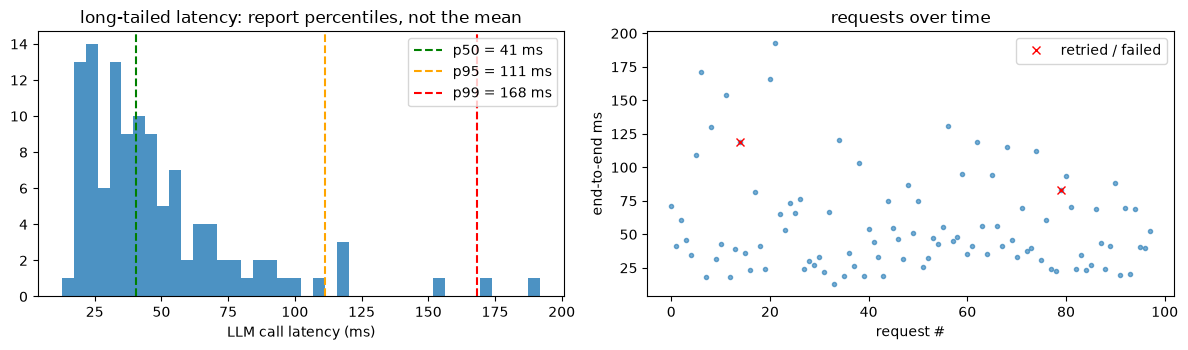

In [8]:
llm_lat = [s.duration_ms for s in tracer.spans if s.kind == "llm"]
req_lat = [s.duration_ms for s in tracer.spans if s.parent_id is None]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(llm_lat, bins=40, color="tab:blue", alpha=.8)
for q, c in [(50, "green"), (95, "orange"), (99, "red")]:
    ax[0].axvline(percentile(llm_lat, q), color=c, ls="--", label=f"p{q} = {percentile(llm_lat, q):.0f} ms")
ax[0].set_xlabel("LLM call latency (ms)"); ax[0].set_title("long-tailed latency: report percentiles, not the mean"); ax[0].legend()
roots = sorted([s for s in tracer.spans if s.parent_id is None], key=lambda s: s.start)
ax[1].plot([s.duration_ms for s in roots], ".", alpha=.6)
errs = [(i, s.duration_ms) for i, s in enumerate(roots) if s.status == "error" or any(e["name"] == "retry" for e in s.events)]
if errs: ax[1].plot(*zip(*errs), "rx", label="retried / failed")
ax[1].set_xlabel("request #"); ax[1].set_ylabel("end-to-end ms"); ax[1].set_title("requests over time"); ax[1].legend()
plt.tight_layout(); plt.show()

Retried requests sit at the top of the right plot: a retry roughly doubles latency. That is the kind of correlation traces make obvious and plain logs hide.

## 5. SLOs and alerts

A **service-level objective** turns metrics into a contract ("95 % of requests under 300 ms, < 2 % errors, < $0.0005 per request"). Alerting fires when a window of traffic violates it.

In [9]:
SLOS = {"p95_ms": 300, "error_rate": 0.02, "cost_per_request_usd": 0.0005}
violations = check_slos(req, SLOS)
print("\n".join(violations) if violations else "all SLOs met")

all SLOs met


## 6. Online evaluation: attach quality scores to traces

Latency and cost are easy; **quality** is what matters. For every request we compute cheap automatic scores and attach them to the trace:
- `groundedness` — share of the answer supported by the retrieved context (faithfulness proxy)
- `correctness` — token-F1 against the reference answer (only possible for labelled traffic; in production: sampled human review or an LLM judge)

Then we query the worst traces — the debugging loop of every LLM team.

In [10]:
by_trace = tracer.traces()
ref_by_question = {}
for t, item in traffic[:120]:
    ref_by_question[t] = item["answer"]
rows = []
for tid, spans in by_trace.items():
    root = next(s for s in spans if s.parent_id is None)
    if root.name != "answer_question" or root.status == "error":
        continue
    a = root.attributes
    g = context_support(a["answer"], a.get("context", ""))
    c = token_f1(a["answer"], ref_by_question.get(a["question"], ""))
    tracer.score(tid, "groundedness", g, source="heuristic"); tracer.score(tid, "correctness", c, source="reference")
    rows.append((c, g, root.duration_ms, a["question"], a["answer"], tid))
cs = [r[0] for r in rows]
print(f"scored {len(rows)} traces | mean correctness (token-F1) {np.mean(cs):.2f} | mean groundedness {np.mean([r[1] for r in rows]):.2f}")
print("\nworst 3 traces by correctness:")
for c, g, ms, q, a, tid in sorted(rows)[:3]:
    print(f"  F1 {c:.2f} | grounded {g:.2f} | {ms:4.0f} ms | Q: {q[:55]}\n     A: {a[:110]}")

scored 81 traces | mean correctness (token-F1) 0.88 | mean groundedness 1.00

worst 3 traces by correctness:
  F1 0.78 | grounded 1.00 |   13 ms | Q: How long does express shipping take?
     A: Express shipping delivers in 1 to 2 business days and costs 15 dollars. [1]
  F1 0.78 | grounded 1.00 |   19 ms | Q: Quick question: How long does express shipping take?
     A: Express shipping delivers in 1 to 2 business days and costs 15 dollars. [1]
  F1 0.78 | grounded 1.00 |   24 ms | Q: Quick question: How long does express shipping take?
     A: Express shipping delivers in 1 to 2 business days and costs 15 dollars. [1]


In [11]:
worst = sorted(rows)[0]
print("drill-down into the worst trace:")
tracer.print_trace(worst[-1], show_attributes=("retrieval.doc_ids",))

drill-down into the worst trace:
trace e3a78efe1d74...  (3 spans, $0.00011)
answer_question              chain         12.6 ms  
  `- retrieve                   retrieval      0.0 ms  retrieval.doc_ids=shipping.md,refund_policy.md,refund_policy.md
  `- llm.complete               llm           12.6 ms  175 in / 14 out tok  $0.00011


The drill-down shows *which* documents were retrieved for the failing request — usually enough to tell a retrieval problem (wrong document) from a generation problem (right document, bad answer).

## 7. Export and sampling

- **JSON Lines** — one span per line, ready for any log pipeline (Loki, Elasticsearch, BigQuery)
- **OTLP** — the OpenTelemetry wire format, accepted by Jaeger, Grafana Tempo, Honeycomb, Datadog, Langfuse, Phoenix
- **Sampling** — at high traffic you keep a fraction of traces (head sampling) and all errors (tail sampling)

In [12]:
import tempfile
path = os.path.join(tempfile.gettempdir(), "traces.jsonl")
n = tracer.export_jsonl(path)
print(f"exported {n} spans to {path} ({os.path.getsize(path) / 1024:.0f} KB); first line:")
print(open(path, encoding="utf-8").readline()[:300], "...")
otlp = tracer.to_otlp()
span0 = otlp["resourceSpans"][0]["scopeSpans"][0]["spans"][0]
print("\nOTLP span keys:", list(span0), "\nfirst attributes:", span0["attributes"][:3])

sampled = Tracer(sample_rate=0.2, seed=0)
for i in range(200):
    with sampled.span("request", kind="chain"):
        pass
print(f"\nhead sampling at 20 %: kept {len(sampled.traces())} of 200 traces")

exported 310 spans to C:\Users\Andy\AppData\Local\Temp\traces.jsonl (298 KB); first line:
{"service": "support-assistant", "name": "retrieve", "kind": "retrieval", "trace_id": "b42933e8c3e444db8ad48f4585dc0a0b", "span_id": "5c3b59af3f744dcf", "parent_id": "0b9e6ecf351f4a42", "start": 1794179201.2966895, "end": 1794179201.2966895, "attributes": {"top_k": 3, "retrieval.doc_ids": "shipping. ...

OTLP span keys: ['traceId', 'spanId', 'parentSpanId', 'name', 'startTimeUnixNano', 'endTimeUnixNano', 'attributes', 'status'] 
first attributes: [{'key': 'top_k', 'value': {'intValue': 3}}, {'key': 'retrieval.doc_ids', 'value': {'stringValue': 'shipping.md,refund_policy.md,refund_policy.md'}}, {'key': 'span.kind', 'value': {'stringValue': 'retrieval'}}]

head sampling at 20 %: kept 33 of 200 traces


## Takeaways

| what to record | why |
|---|---|
| a trace per request, a span per step (LLM, retrieval, tool) | debugging, latency breakdown |
| model, tokens in/out, cost per LLM span | cost control, regression detection after prompt changes |
| prompts and responses — **redacted** | reproducing bad answers without leaking personal data |
| errors, retries, stop reasons as span events | reliability, alerting |
| quality scores attached to traces | finding bad answers, tracking quality over time |

- Report **p50/p95/p99**, never only the mean; set **SLOs** and alert on them.
- Quality needs its own signals: heuristics on every trace, LLM judges on a sample, human review on the worst — and an offline eval set to test changes before they ship (notebooks 10, 13).
- Production stack: OpenTelemetry SDK (+ GenAI semantic conventions) → Langfuse / LangSmith / Phoenix for traces and evals, Prometheus + Grafana for metrics and alerts.

**Next:** `16_mcp_model_context_protocol.ipynb`.